<a href="https://colab.research.google.com/github/leon72305-source/26007815_tb1/blob/main/26007815_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UFCE3R-30-3 - Big Data Analytics
# TB1 Final Assessment (25 marks)

For this assessment, you will need Python and PySpark. We strongly recommend using Google Colab. You may use UWE PCs as well, as we have already covered these topics in both environments. However, we cannot guarantee that automatic updates on UWE PCs will keep library versions aligned.

The assessment has four sections:

- **Section A** - Descriptive analytics (Python/pandas)
- **Section B** - Data visualisation (matplotlib & seaborn)
- **Section C** - Diagnostic analytics: anomaly detection and correlation analysis (Python)
- **Section D** - Big data analysis with PySpark

### Notice 1
Please DO NOT change (add/remove) cells in this notebook. Only write your codes and your comments/reflections in the specified cells. Changing the layout of the notebook/cells, will affect your mark. As stated in the assessment brief, the total number of words in Markdown cells in this Jupyter Notebook needs to be within the specified limit. Please note that this notebook already holds 3333 words in its Markdown cells. When counting words, ignore this amount. You are provided a Jupyter Notebook named `Markdown_word_count.ipynb` to count the number of words in Markdown cells.

### Notice 2
Where requested, add at least 1 test case to verify correctness of your code. Add test cases ONLY in the provided cells.

### Notice 3
To achieve higher marks (optional), you would create a repository (such as in Github) for this assessment and commit gradual progress there. Share the link of the repo in the next cell. If your repo is private, share it with the email of all lecturers:

`Xiaodong.Li@uwe.ac.uk`

`Alireza.Bolhari@uwe.ac.uk`

### Notice 4
Section D uses a dataset with several million rows. Do NOT load it with pandas: this may crash your session and it will not be marked as a big data solution.

==================================================

## Please write your full name and student ID here:

### Full name: Alexander Leonard Gotama
### Student ID: 26007815
### Repo URL: https://github.com/leon72305-source/26007815_tb1

==================================================

## *Datasets Description*

For this assessment, you are going to work with these 2 datasets:
1) CSV: hourly electricity generation, load and prices in Spain (`spain_energy_hourly.csv`), used in Sections A, B and C
2) CSV / PARQUET (two identical formats for this dataset. You can choose which one to work on): fuel prices at petrol stations across France (`fuel_in_france_2026_01_to_2026_09.csv` or `fuel_in_france_2026_01_to_2026_09.parquet`), used in Section D

You can download these datasets from BlackBoard.

A brief description about these datasets:

- 1: this dataset holds 4 years of hourly data (2015-2018) about the Spanish electricity system. Each row is one hour. Columns starting with `generation` hold the electricity generated by each source (MW). `forecast ... day ahead` columns hold the forecasts made one day before. `total load forecast` and `total load actual` hold the forecast and actual electricity demand (MW). `price day ahead` and `price actual` hold electricity prices (EUR/MWh).

Link to the original dataset: https://huggingface.co/datasets/vitaliy-sharandin/energy-consumption-hourly-spain

- 2: this dataset holds fuel price records from petrol stations across France, from January to September 2026 (several million rows). Each row is one price record of one fuel type at one station, together with the Brent crude oil price. The original dataset is updated daily. Column names are in French, so use the data dictionary below.

Link to the original dataset: https://huggingface.co/datasets/VincentGOURBIN/FuelInFranceData

| Column | Meaning |
| ----------- | ----------- |
| `rate_date` | Date and time of the price record (`dd/MM/yyyy HH:mm`) |
| `station_id` | Unique identifier of the station |
| `nom` | Name of the station |
| `commune` | Town / municipality |
| `marque` | Brand of the station |
| `departement` | French department code (e.g. `01`, `2A`) |
| `regioncode` | French region code |
| `zipcode` | Postcode (French postcodes have 5 characters and may start with `0`) |
| `address` | Street address |
| `coordlatitude`, `coordlongitude` | Location of the station |
| `fuel_name` | Fuel type (`Gazole` = diesel, `SP95`, `SP98`, `E10`, `E85`, `GPLc` = LPG) |
| `price` | Price of the fuel (EUR per litre) |
| `brent_date` | Date of the Brent crude oil price |
| `brent_rate` | Brent crude oil price (USD per barrel) |
| `brent_rate_eur` | Brent crude oil price (EUR per barrel) |
| `source_file` | Name of the monthly file the record was collected from |

## Uploading datasets to Colab

You may upload `.zip` version of the datasets to Colab and then unzip them using Python code. For instance, to unzip `file_name.zip`:

```
import zipfile

with zipfile.ZipFile('file_name.zip', 'r') as zip_ref:
    zip_ref.extractall('.')
```

As `fuel_in_france_2026_01_to_2026_09.zip` is a large file, give enough time for the upload to finish. Alternatively, you may put it in your Google Drive and mount the drive in Colab.

In [1]:
# If you need to unzip files
import zipfile

# Unzips each file individually
with zipfile.ZipFile('fuel_in_france_2026_01_to_2026_09_parquet.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

with zipfile.ZipFile('fuel_in_france_2026_01_to_2026_09_csv.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

with zipfile.ZipFile('spain_energy_hourly.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

## Environment Setup

Please ensure you have PySpark installed. If you need to install it (or any other library), use this cell. The `-q` flag keeps the output quiet.

In [2]:
# BEGIN SOLUTION
#-q is utilized to mute installation details
!pip install -q pyspark

# END SOLUTION

If you need to `import` anything, please ONLY use this cell to put ALL the `import` statements for this notebook:

In [45]:
# Put ALL the import statements for this notebook in this cell.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession

import time
import pyspark.sql.functions as F
from pyspark.sql.types import StringType, DoubleType, DateType

# Section A: Descriptive Analytics

Descriptive analytics is the first step in understanding data: summarising and presenting it in a meaningful way. In this section you will use pandas and the `spain_energy_hourly.csv` dataset.

## 1: Loading the energy dataset

Write a Python code to load `spain_energy_hourly.csv` into a pandas DataFrame named `df_energy`. Convert the `time` column into a proper datetime type and set it as the index of the DataFrame. Then display the first 10 and the last 10 rows, and print the shape (number of rows and columns) of the DataFrame.

Note: the `time` column holds timestamps with different UTC offsets (`+01:00` in winter and `+02:00` in summer). Something like `pd.to_datetime(..., utc=True)` followed by `.tz_convert('Europe/Madrid')` may help.

In [4]:
# BEGIN SOLUTION
df_energy = pd.read_csv('spain_energy_hourly.csv')

#Converts the different timezones into a single timeline
df_energy['time'] = pd.to_datetime(df_energy['time'], utc=True).dt.tz_convert('Europe/Madrid')

#Converts integer index into a row index
df_energy.set_index('time', inplace=True)

display("First 10 rows:", df_energy.head(10))
display("Last 10 rows:", df_energy.tail(10))

#Displays total number of rows and columns
print("Dataframe shape (rows, columns):",df_energy.shape)
# END SOLUTION

'First 10 rows:'

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,NaN,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,NaN,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,NaN,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
2015-01-01 03:00:00+01:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,NaN,...,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
2015-01-01 04:00:00+01:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,NaN,...,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04
2015-01-01 05:00:00+01:00,410.0,178.0,0.0,4038.0,3590.0,156.0,0.0,0.0,0.0,NaN,...,188.0,0.0,4618.0,4.0,NaN,4617.0,21441.0,19905.0,35.72,53.63
2015-01-01 06:00:00+01:00,401.0,172.0,0.0,4040.0,3368.0,158.0,0.0,0.0,0.0,NaN,...,186.0,0.0,4397.0,3.0,NaN,4276.0,21285.0,20010.0,35.13,51.73
2015-01-01 07:00:00+01:00,408.0,172.0,0.0,4030.0,3208.0,160.0,0.0,0.0,0.0,NaN,...,189.0,0.0,3992.0,12.0,NaN,3994.0,21545.0,20377.0,36.22,51.43
2015-01-01 08:00:00+01:00,413.0,177.0,0.0,4052.0,3335.0,161.0,0.0,0.0,0.0,NaN,...,198.0,0.0,3629.0,39.0,NaN,3602.0,21443.0,20094.0,32.40,48.98


'Last 10 rows:'

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,,,,,
2018-12-31 14:00:00+01:00,297.0,0.0,0.0,6062.0,2698.0,212.0,0.0,0.0,0.0,NaN,...,294.0,0.0,2289.0,3997.0,NaN,2084.0,27749.0,27988.0,64.97,71.95
2018-12-31 15:00:00+01:00,295.0,0.0,0.0,6128.0,2501.0,178.0,0.0,0.0,0.0,NaN,...,287.0,0.0,2233.0,3763.0,NaN,2101.0,26955.0,27009.0,64.18,70.85
2018-12-31 16:00:00+01:00,300.0,0.0,0.0,6379.0,2503.0,178.0,0.0,0.0,0.0,NaN,...,294.0,0.0,2267.0,2841.0,NaN,2283.0,26527.0,26449.0,64.80,71.36
2018-12-31 17:00:00+01:00,298.0,0.0,0.0,6892.0,2583.0,177.0,0.0,0.0,0.0,NaN,...,296.0,0.0,2550.0,1318.0,NaN,2607.0,27293.0,26738.0,68.01,75.13
2018-12-31 18:00:00+01:00,293.0,0.0,0.0,7593.0,2604.0,178.0,0.0,0.0,0.0,NaN,...,289.0,0.0,2952.0,300.0,NaN,3028.0,29690.0,29592.0,68.58,77.61
2018-12-31 19:00:00+01:00,297.0,0.0,0.0,7634.0,2628.0,178.0,0.0,0.0,0.0,NaN,...,277.0,0.0,3113.0,96.0,NaN,3253.0,30619.0,30653.0,68.85,77.02
2018-12-31 20:00:00+01:00,296.0,0.0,0.0,7241.0,2566.0,174.0,0.0,0.0,0.0,NaN,...,280.0,0.0,3288.0,51.0,NaN,3353.0,29932.0,29735.0,68.40,76.16
2018-12-31 21:00:00+01:00,292.0,0.0,0.0,7025.0,2422.0,168.0,0.0,0.0,0.0,NaN,...,286.0,0.0,3503.0,36.0,NaN,3404.0,27903.0,28071.0,66.88,74.30
2018-12-31 22:00:00+01:00,293.0,0.0,0.0,6562.0,2293.0,163.0,0.0,0.0,0.0,NaN,...,287.0,0.0,3586.0,29.0,NaN,3273.0,25450.0,25801.0,63.93,69.89


Dataframe shape (rows, columns): (35064, 28)


In [5]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.

#Checks if variable df_energy is an instance of pd dataframe
assert isinstance(df_energy, pd.DataFrame), "Error: df_energy is not a pandas dataframe"

#Extracts timezone info and turns it into string like EU/madrid to compare
assert str(df_energy.index.tz) == 'Europe/Madrid', "Error: df_energy.index is not in EU/Madrid timezone"

#Returns tuple with number of rows and columns
assert df_energy.shape[0] > 0 and df_energy.shape[1] > 0, "Error: df_energy is empty"
print("All test cases passed, dataset is properly loaded!")


All test cases passed, dataset is properly loaded!


## 2: Data types and data quality audit

Using `df_energy`:
- print the data type of each column
- print the number AND the percentage of missing values in each column
- identify the columns that are **entirely** missing and the columns whose values are **all zero**
- check whether there are any duplicate timestamps

Store the names of the columns that hold no useful information in a list named `cols_to_drop`, then drop them and save the result in a new DataFrame named `df_clean`.

In [6]:
# BEGIN SOLUTION
#Displays data types for every column
print("---Column Data Types---")
dtypes_df = df_energy.dtypes.to_frame(name='Data Type')
display(dtypes_df)

#Inserts blank space and divides display of output types
print("\n" + "="*40 + "\n")

#Scans table for missing values that is classed to true or false for total count
missing_count = df_energy.isnull().sum()

#Calculates average of 1s (true) and 0s (false) into percentage
missing_percentage = (df_energy.isnull().mean() * 100).round(2)

#Creates new summary table
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percentage
})
print("---Missing Values Summary---")
display (missing_summary)
print("\n" + "="*40 + "\n")

#Creates python list and filters column names
entirely_missing = df_energy.columns[df_energy.isnull().all()].tolist()
all_zero = df_energy.columns[(df_energy == 0).all()].tolist()

print("Entirely missing columns:", entirely_missing)
print("All zero columns:", all_zero)
print("\n" + "="*40 + "\n")

#Counts amount of duplicated timestamps in dataset
duplicate_timestamps = df_energy.index.duplicated().sum()
print(f"Number of duplicate timestamps: {duplicate_timestamps}")
if duplicate_timestamps > 0:
  print("Duplicate timestamps found!")
else:
  print("No duplicate timestamps found!")
print("\n" + "="*40 + "\n")

#Combines two list into one
cols_to_drop = list(set(entirely_missing + all_zero))
print(f"Columns to drop: {cols_to_drop}")

#Creates new dataset called df_clean
df_clean = df_energy.drop(columns=cols_to_drop)
print(f"New dataframe 'df_clean' shape: {df_clean.shape}")


# END SOLUTION

---Column Data Types---


,Data Type
generation biomass,float64
generation fossil brown coal/lignite,float64
generation fossil coal-derived gas,float64
generation fossil gas,float64
generation fossil hard coal,float64
generation fossil oil,float64
generation fossil oil shale,float64
generation fossil peat,float64
generation geothermal,float64
generation hydro pumped storage aggregated,float64




---Missing Values Summary---


,Missing Count,Missing Percentage (%)
generation biomass,19,0.05
generation fossil brown coal/lignite,18,0.05
generation fossil coal-derived gas,18,0.05
generation fossil gas,18,0.05
generation fossil hard coal,18,0.05
generation fossil oil,19,0.05
generation fossil oil shale,18,0.05
generation fossil peat,18,0.05
generation geothermal,18,0.05
generation hydro pumped storage aggregated,35064,100.00




Entirely missing columns: ['generation hydro pumped storage aggregated', 'forecast wind offshore eday ahead']
All zero columns: []


Number of duplicate timestamps: 0
No duplicate timestamps found!


Columns to drop: ['generation hydro pumped storage aggregated', 'forecast wind offshore eday ahead']
New dataframe 'df_clean' shape: (35064, 26)


In [7]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.

#Checks for missing and zero values in df_clean
assert df_clean.isnull().all().sum() == 0, "Error: df_clean has missing values"
assert ((df_clean == 0).all()).sum() == 0, "Error: df_clean has all zero values"

print("All test cases passed, dataset is properly loaded!")

All test cases passed, dataset is properly loaded!


What data quality issues did you find? Why is it justified to drop the columns in `cols_to_drop`? Write your answer in the Markdown cell below.

#### START.
Your analysis / interpretation goes here:

As dropped columns were entirely missing values or had all-zero columns, it was justified as they serve no purpose to the table as they hold no relevant information or impacts.



#### END.

## 3: Handling the remaining missing values

Some columns in `df_clean` might still have a small number of missing values. Handle them using a method that is appropriate for **hourly time-series** data. Print the number of missing values in each column before and after your treatment.

In [8]:
# BEGIN SOLUTION
# Your code here with comments or explanation
print("---Missing values before treatment---")

#Creates two-column dataframe and column title
missing_before = df_clean.isnull().sum()
display(missing_before.to_frame(name='Original Missing Count'))
print("\n" + "="*40 + "\n")

#Estimates missing data from similar values and filling gaps in the dataset
df_clean = df_clean.interpolate(method='linear').ffill().bfill()

#Confirms values filled and displays updated table
print("---Missing values after treatment---")
missing_after = df_clean.isnull().sum()
display(missing_after.to_frame(name='Missing Count after treatment'))
# END SOLUTION

---Missing values before treatment---


,Original Missing Count
generation biomass,19
generation fossil brown coal/lignite,18
generation fossil coal-derived gas,18
generation fossil gas,18
generation fossil hard coal,18
generation fossil oil,19
generation fossil oil shale,18
generation fossil peat,18
generation geothermal,18
generation hydro pumped storage consumption,19




---Missing values after treatment---


,Missing Count after treatment
generation biomass,0
generation fossil brown coal/lignite,0
generation fossil coal-derived gas,0
generation fossil gas,0
generation fossil hard coal,0
generation fossil oil,0
generation fossil oil shale,0
generation fossil peat,0
generation geothermal,0
generation hydro pumped storage consumption,0


In [9]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.

#Ensure that total amount of missing values in dataframe is 0
total_missing = df_clean.isnull().sum().sum()
assert total_missing == 0, "Error: df_clean still has missing values"
assert df_clean.shape[0] > 0 and df_clean.shape[1] > 0, "Error: df_clean has invalid shape"

print("All test cases passed, there are no more missing values!")

All test cases passed, there are no more missing values!


Why did you choose this method? Why could filling with the column mean, or dropping the rows, be less appropriate here? Write your answer in the Markdown cell below.

#### START.
Your analysis / interpretation goes here:

Because dropping values could impact the validity of the table if another value relies on it. Additionally, replacing flat values may impact the natural variance that distorts the dataset.

#### END.

## 4: Summary statistics

For `df_clean`:
- calculate summary statistics (count, mean, standard deviation, minimum, quartiles, maximum) for all numerical columns
- calculate the mode and the range of `total load actual` and `price actual`
- calculate the skewness of `price actual`

In [10]:
# BEGIN SOLUTION
#Create statistical summary for all numerical columns
print("--- Summary Statistics (Numerical Columns) ---")
summary_stats = df_clean.describe()
display(summary_stats)
print("\n" + "="*40 + "\n")

#Creates list of column names
target_cols = ['total load actual', 'price actual']

#Calculate mode for total load actual and price actual
print("--- Mode ---")
mode_values = df_clean[target_cols].mode()
display(mode_values)
print("\n" + "="*40 + "\n")

#Calculate range for total load actual and price actual
print("--- Range ---")
range_values = df_clean[target_cols].max() - df_clean[target_cols].min()

#Converts single column list into proper dataframe table
display(range_values.to_frame(name='Range'))
print("\n" + "="*40 + "\n")

#Calculate the assymetrical distribution of price actual
price_skewness = df_clean['price actual'].skew()
print(f"Skewness of 'price actual': {price_skewness}")

# END SOLUTION

--- Summary Statistics (Numerical Columns) ---


,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,...,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
count,35064.000000,35064.000000,35064.0,35064.000000,35064.000000,35064.000000,35064.0,35064.0,35064.0,35064.000000,...,35064.000000,35064.000000,35064.0,35064.000000,35064.000000,35064.000000,35064.000000,35064.000000,35064.000000,35064.000000
mean,383.531343,448.094570,0.0,5622.700647,4256.531271,298.342417,0.0,0.0,0.0,475.582706,...,1432.818546,269.418692,0.0,5464.980450,1439.066735,5471.216689,28712.129962,28698.281385,49.874341,57.884023
std,85.346266,354.618269,0.0,2201.510984,1961.988937,52.519927,0.0,0.0,0.0,792.312704,...,1679.961733,50.218423,0.0,3213.586296,1677.703355,3176.312853,4594.100854,4575.828854,14.618900,14.204083
min,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,237.000000,18105.000000,18041.000000,2.060000,9.330000
25%,333.000000,0.000000,0.0,4126.000000,2527.000000,263.000000,0.0,0.0,0.0,0.000000,...,71.000000,240.000000,0.0,2933.000000,69.000000,2979.000000,24793.750000,24807.000000,41.490000,49.347500
50%,367.000000,509.000000,0.0,4969.500000,4475.000000,300.000000,0.0,0.0,0.0,68.000000,...,616.000000,279.000000,0.0,4849.500000,576.000000,4855.000000,28906.000000,28902.000000,50.520000,58.020000
75%,433.000000,757.000000,0.0,6429.000000,5839.000000,330.000000,0.0,0.0,0.0,616.000000,...,2579.000000,310.000000,0.0,7399.500000,2636.000000,7353.000000,32263.250000,32194.250000,60.530000,68.010000
max,592.000000,999.000000,0.0,20034.000000,8359.000000,449.000000,0.0,0.0,0.0,4523.000000,...,5792.000000,357.000000,0.0,17436.000000,5836.000000,17430.000000,41390.000000,41015.000000,101.990000,116.800000




--- Mode ---


,total load actual,price actual
0,23665.0,56.85




--- Range ---


,Range
total load actual,22974.00
price actual,107.47




Skewness of 'price actual': -0.32374928779368645


#### START.
Describe the outputs (remember the units: MW and EUR/MWh):

EMPTY


#### END.

## 5: Feature engineering

Add these new columns to `df_clean`:
- `year`, `month`, `hour` and `day_of_week`, derived from the (local time) index
- `fossil_generation` = sum of `generation fossil brown coal/lignite`, `generation fossil gas`, `generation fossil hard coal` and `generation fossil oil`
- `renewable_generation` = sum of `generation biomass`, `generation hydro run-of-river and poundage`, `generation hydro water reservoir`, `generation other renewable`, `generation solar` and `generation wind onshore`
- `total_generation` = sum of all remaining `generation ...` columns, **excluding** `generation hydro pumped storage consumption` (this column is electricity consumed for pumping, not generated)
- `renewable_share` = `renewable_generation` / `total_generation` x 100
- `load_forecast_error` = `total load actual` - `total load forecast`

In [11]:
# BEGIN SOLUTION

#Extracts datettime attributes from local time indexes
df_clean['year'] = df_clean.index.year
df_clean['month'] = df_clean.index.month
df_clean['hour'] = df_clean.index.hour
df_clean['day_of_week'] = df_clean.index.dayofweek

#Calculates total for fossil generation
fossils_cols = ['generation fossil brown coal/lignite',
                'generation fossil gas',
                'generation fossil hard coal',
                'generation fossil oil']

#Enforces pandas to sum horizontally instead of vertical
df_clean['fossil_generation'] = df_clean[fossils_cols].sum(axis=1)

#Calculates total for renewable generation
renewable_cols = ['generation biomass',
                  'generation hydro run-of-river and poundage',
                  'generation hydro water reservoir',
                  'generation other renewable',
                  'generation solar',
                  'generation wind onshore']
df_clean['renewable_generation'] = df_clean[renewable_cols].sum(axis=1)

gen_columns = [
    #Compact loop that goes by names individually to filter off conditions
    col for col in df_clean.columns

    #Uses key words to filter out specific columns not included in the new one
    if col.startswith('generation') and col not in [
        'generation hydro pumped storage consumption',
        'fossil_generation',
        'renewable_generation']
]
df_clean['total_generation'] = df_clean[gen_columns].sum(axis=1)

#Displays percentages from division of columns
df_clean['renewable_share'] = (df_clean['renewable_generation'] / df_clean['total_generation']) * 100

#Cleans up datasets by replacing non numerical values with a 0 instead
df_clean['renewable_share'] = df_clean['renewable_share'].fillna(0)

#Calculates load forecast error
df_clean['load_forecast_error'] = df_clean['total load actual'] - df_clean['total load forecast']

#Displays the new df_clean dataframe table
print("New columns successfully added!")
display(df_clean[['year', 'month', 'hour', 'day_of_week',
                  'fossil_generation',
                  'renewable_generation',
                  'total_generation',
                  'renewable_share',

                  #Shows first 5 rows of dataframe
                  'load_forecast_error']].head())
# END SOLUTION

New columns successfully added!


,year,month,hour,day_of_week,fossil_generation,renewable_generation,total_generation,renewable_share,load_forecast_error
time,,,,,,,,,
2015-01-01 00:00:00+01:00,2015,1,0,3,10156.0,9897.0,27388.0,36.136264,-733.0
2015-01-01 01:00:00+01:00,2015,1,1,3,10437.0,9127.0,26898.0,33.931891,-552.0
2015-01-01 02:00:00+01:00,2015,1,2,3,9918.0,8376.0,25632.0,32.677903,-781.0
2015-01-01 03:00:00+01:00,2015,1,3,3,8859.0,7529.0,23720.0,31.741147,-1356.0
2015-01-01 04:00:00+01:00,2015,1,4,3,8313.0,7152.0,22794.0,31.376678,-1521.0


In [12]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.



## 6: Data grouping and aggregation

a) Group the data by `year` and calculate: the mean `price actual`, the mean `total load actual`, the total `renewable_generation` in GWh (hint: each row is one hour, so summing MW gives MWh), and the mean `renewable_share`.

b) Group the data by `hour` and calculate the mean `total load actual` and the mean `price actual`. Which hour of the day has the highest average demand, and which has the highest average price?

c) Which month (year and month) had the highest average `price actual`? Which month had the highest average `renewable_share`?

In [13]:
# BEGIN SOLUTION
#Verify that all engineered columns are in the dataframe
expected_cols = [
    'year', 'month', 'hour', 'day_of_week', 'fossil_generation',
    'renewable_generation', 'renewable_share', 'load_forecast_error'
]

#Ensure that all columns are added to df_clean
for col in expected_cols:
  assert col in df_clean.columns, f"Error: The column '{col}' is missing from df_clean"

#Ensure that all percentages are valid and between 0 to 100%
assert df_clean['renewable_share'].between(0, 100).all(), "Error: renewable_share has invalid values"
print("All test cases passed, there are no more missing values!")

# END SOLUTION

All test cases passed, there are no more missing values!


#### START.
Describe the outputs:

EMPTY

#### END.

# Section B: Data Visualisation

All charts must have a proper title, axis names (with units where applicable), legends where needed and readable tick labels. Use comments (begin with #) to explain your coding work. Use **matplotlib** for questions 7 and 8, and **seaborn** for question 9.

### 7: Time-series chart (matplotlib)

Resample the hourly data to **daily** averages. In one figure with two vertically stacked subplots that share the x-axis, plot:
- top: the daily average `price actual`, together with its 30-day rolling mean
- bottom: the daily average `total load actual`

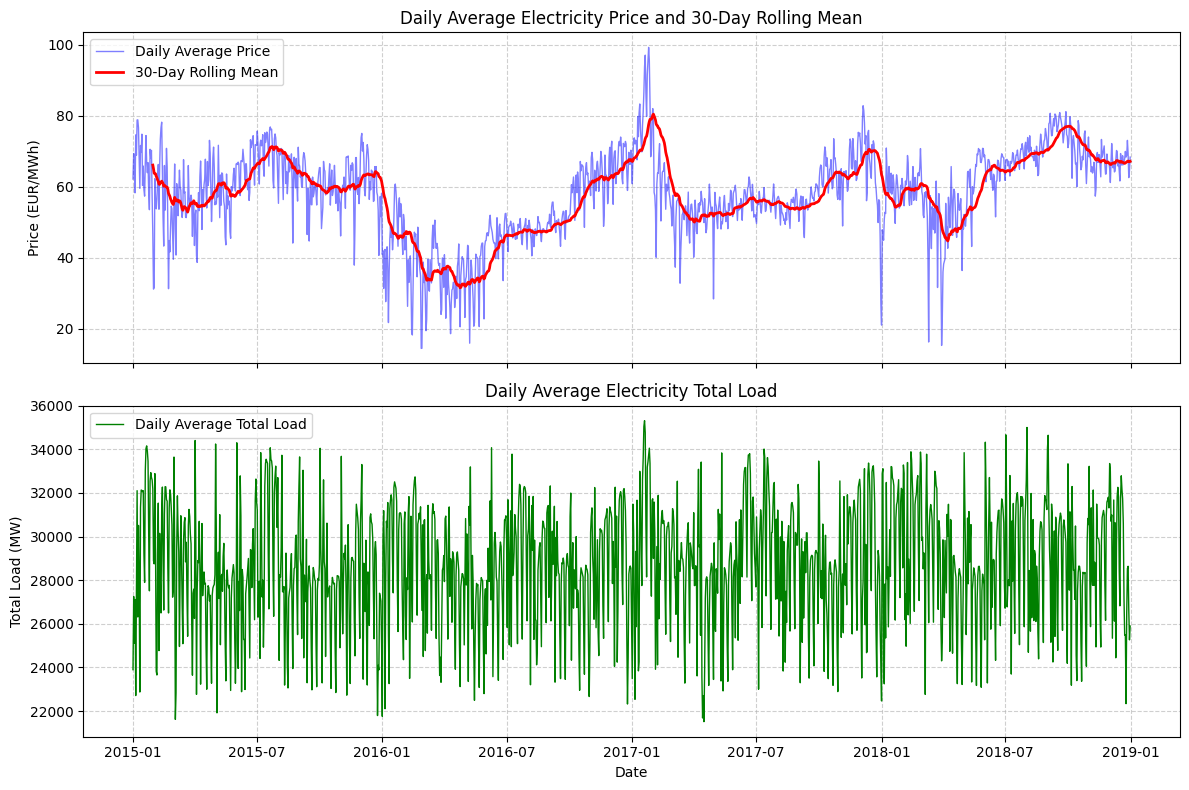

In [14]:
# BEGIN SOLUTION
#Converts hourly data into daily ('D')
df_daily = df_clean.resample('D').mean()

#Calculates mean over the 30 day rolling period to reveal trends
df_daily['price_rolling_30d'] = df_daily['price actual'].rolling(window=30).mean()

#Sets up separate figures within a single stacked chart
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(12, 8), sharex=True)

#Sets up the top supblot of daily avereage price actual alongside its 30 day rolling mean
ax1.plot(df_daily.index, df_daily['price actual'], label='Daily Average Price', color='blue', alpha=0.5, linewidth=1)
ax1.plot(df_daily.index, df_daily['price_rolling_30d'], label='30-Day Rolling Mean', color='red', linewidth=2)
ax1.set_title('Daily Average Electricity Price and 30-Day Rolling Mean')
ax1.set_ylabel('Price (EUR/MWh)', fontsize=10)
ax1.legend(loc='upper left')

#Controls style and transparency of lines
ax1.grid(True, linestyle='--', alpha=0.6)

#Sets up the bottom subplot of daily average total load actual
ax2.plot(df_daily.index, df_daily['total load actual'], label='Daily Average Total Load', color='green', linewidth=1)
ax2.set_title('Daily Average Electricity Total Load')
ax2.set_ylabel('Total Load (MW)', fontsize=10)
ax2.set_xlabel('Date', fontsize=10)
ax2.legend(loc='upper left')

#Controls style and transparency of lines
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# END SOLUTION

#### START.
Describe the chart:



#### END.

## 8: Generation mix (matplotlib)

In one figure with two subplots, create:
- a **stacked area chart** of the monthly total generation (in GWh) from `generation nuclear`, `fossil_generation`, `renewable_generation` and "other" (everything else in `total_generation`)
- a **pie chart** showing the share of each of these four groups in the total generation over the whole period

/tmp/ipykernel_3919/1349392683.py:14: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_monthly = df_clean[gen_groups].resample('M').sum() / 1000.0


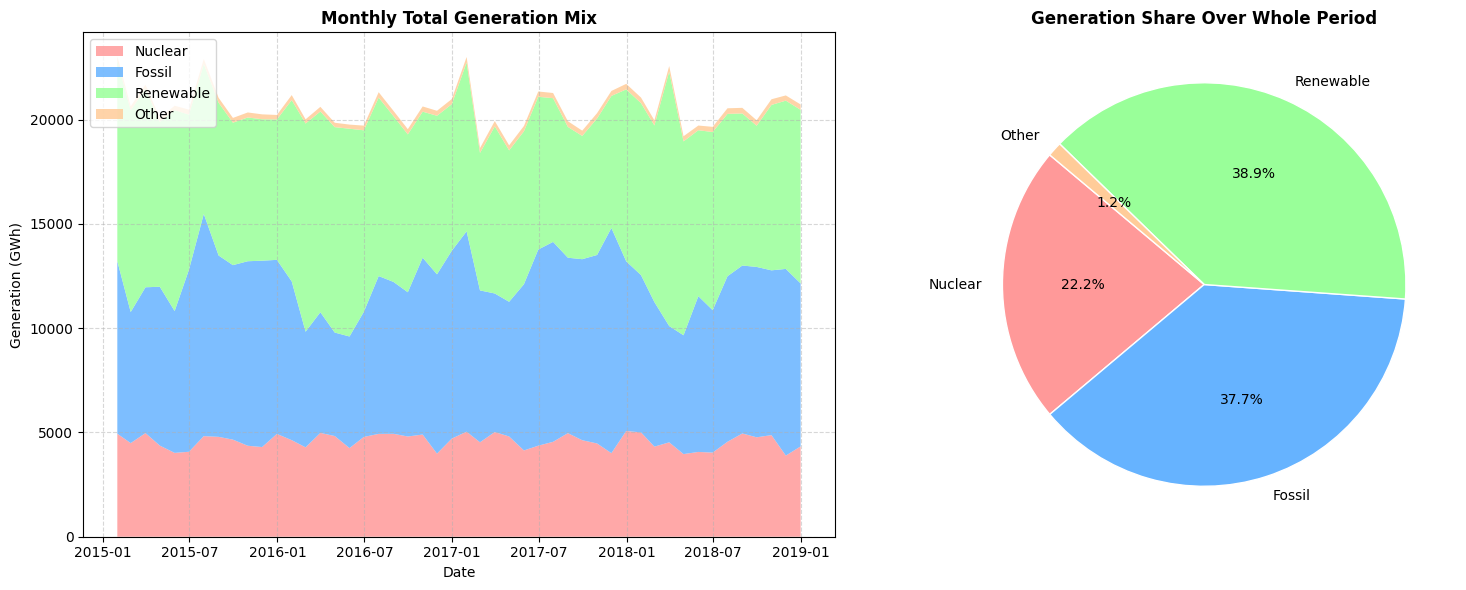

In [15]:
# BEGIN SOLUTION
#Sums up everything in total_generation except nuclear, fossil, and renewable
df_clean['other_generation'] = df_clean['total_generation'] - (
    df_clean.get('generation nuclear',0) +
    df_clean['fossil_generation'] +
    df_clean['renewable_generation']
)

#Defines the four groups
gen_groups = ['generation nuclear', 'fossil_generation', 'renewable_generation', 'other_generation']
group_labels = ['Nuclear','Fossil','Renewable','Other']

#Converts MWh to GWh by summing up hourly production numbers
df_monthly = df_clean[gen_groups].resample('M').sum() / 1000.0
df_monthly.columns = group_labels

#Sets up figure with two side by side subplots
fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

#Stacks column on top of column chronologically
ax1.stackplot(
    df_monthly.index,
    [df_monthly[col]for col in group_labels],
    labels=group_labels,
    alpha=0.85,
    colors=['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']
)
ax1.set_title('Monthly Total Generation Mix', fontsize=12, fontweight='bold')
ax1.set_xlabel('Date', fontsize=10)
ax1.set_ylabel('Generation (GWh)', fontsize=10)
ax1.legend(loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.5)

#Sets up 2nd subplot
total_period_gen = df_clean[gen_groups].sum() / 1000.0

ax2.pie(
    total_period_gen,
    labels=group_labels,

    #Formats percentage of each pie chart to one decimal place
    autopct='%1.1f%%',
    startangle=140,
    colors=['#ff9999', '#66b3ff', '#99ff99', '#ffcc99'],

    #Customizes visual appearance
    wedgeprops={'edgecolor':'white','linewidth':1}
)
#Creates title for piechart
ax2.set_title('Generation Share Over Whole Period', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# END SOLUTION

#### START.
Describe the charts:



#### END.

## 9: Patterns and distributions (seaborn)

Create one figure with a 2 x 2 grid of subplots:
- (a) a box plot of `price actual` for each `month`
- (b) a heatmap of the mean `total load actual` for each `hour` (rows) and `day_of_week` (columns)
- (c) a histogram with a KDE curve of `price actual`
- (d) a scatter plot of `total load actual` (x) against `price actual` (y), coloured by `renewable_share`. Use a random sample of 5,000 rows (`random_state=42`) to keep the chart readable.

/tmp/ipykernel_3919/2832167660.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


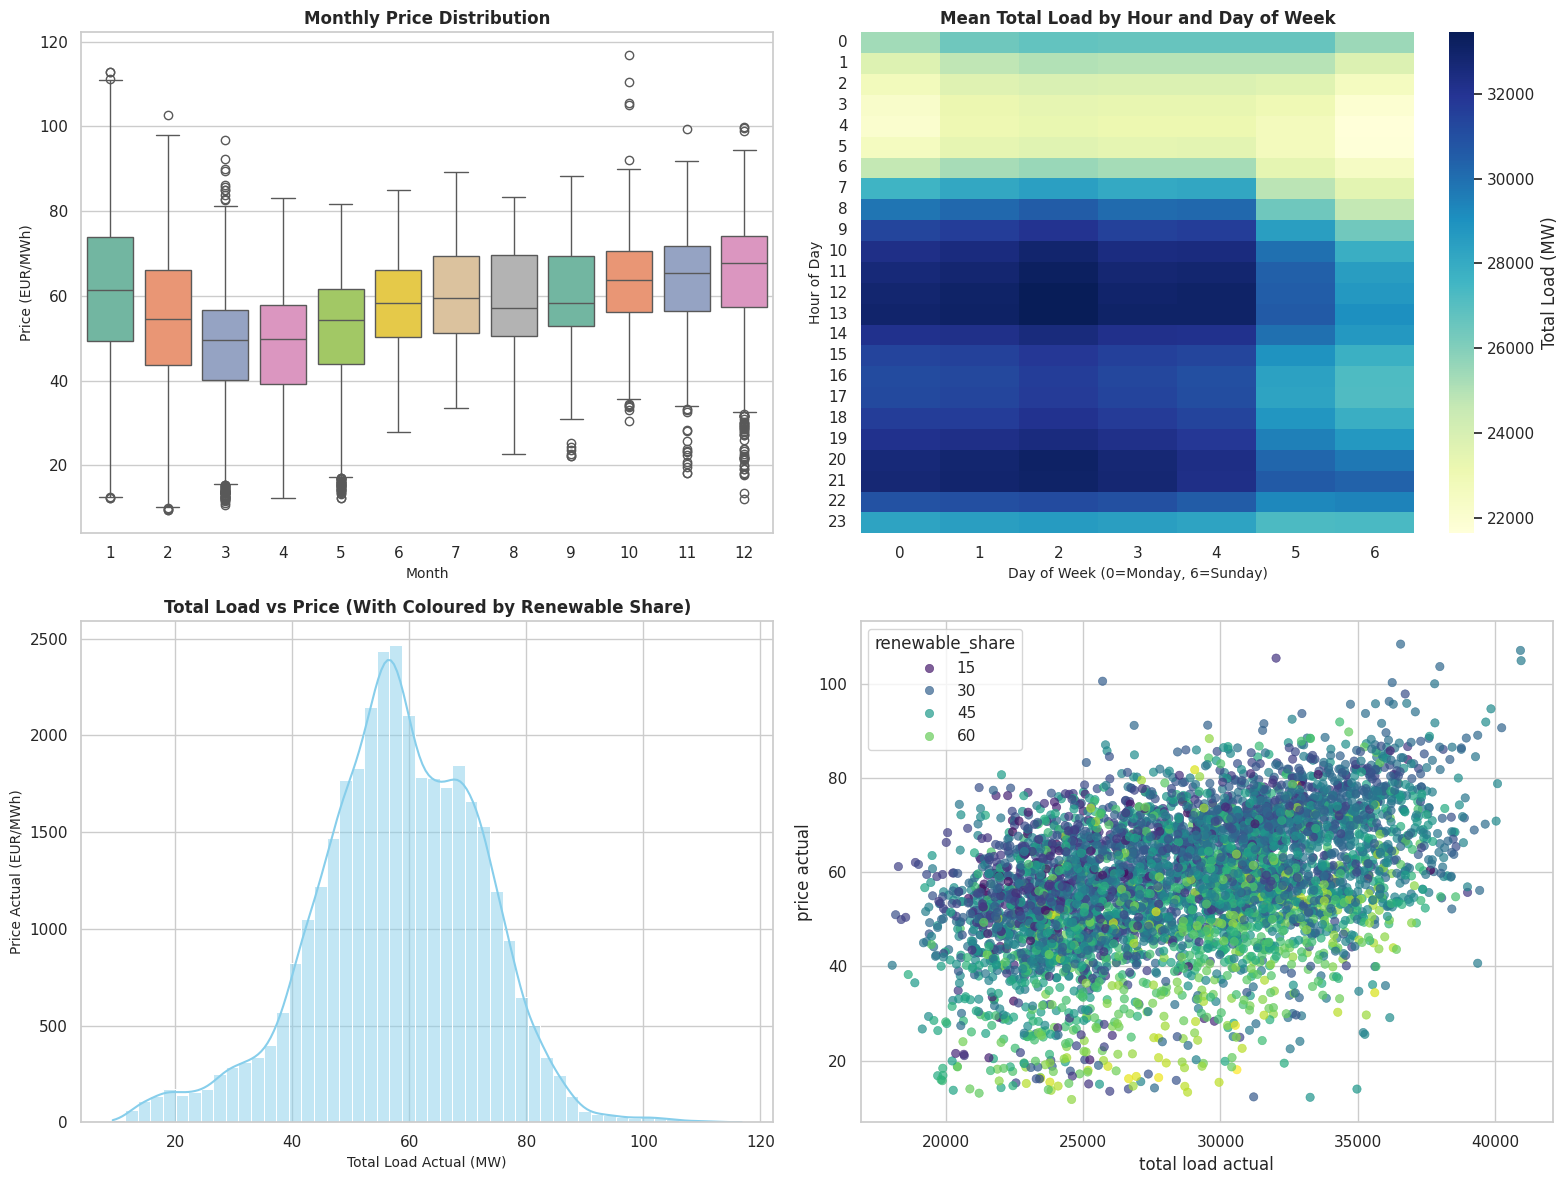

In [16]:
# BEGIN SOLUTION
#Sets visual style for seaborn
sns.set_theme(style='whitegrid')

#Creates figure with 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))

#Sets box plot of price actual
sns.boxplot(

    #Extracts data from df_clean
    data=df_clean,
    x='month',
    y='price actual',

    #Determines where chart is drawn into
    ax=axes[0,0],
    palette='Set2'
)
axes[0,0].set_title('Monthly Price Distribution', fontsize=12, fontweight='bold')
axes[0,0].set_xlabel('Month', fontsize=10)
axes[0,0].set_ylabel('Price (EUR/MWh)', fontsize=10)

#Creates heatmap by pivoting data to a 2d matrix of hours vs days
load_heatmap_data = df_clean.pivot_table(
    index='hour',
    columns='day_of_week',
    values='total load actual',
    aggfunc='mean'
)
sns.heatmap(
    load_heatmap_data,
    ax=axes[0,1],

    #Sets up colormap for heatmaps
    cmap='YlGnBu',
    cbar_kws={'label': 'Total Load (MW)'}
)
axes[0,1].set_title('Mean Total Load by Hour and Day of Week', fontsize=12, fontweight='bold')
axes[0,1].set_xlabel('Day of Week (0=Monday, 6=Sunday)', fontsize=10)
axes[0,1].set_ylabel('Hour of Day', fontsize=10)

sns.histplot(
    data=df_clean,
    x='price actual',
    ax=axes[1,0],

    #Enables smooth continuous curve on histogram bars
    kde=True,
    color='skyblue',

    #Controls amount of vertical bars data is split into
    bins=50
)
axes[1,0].set_title('Price Distribution and KDE', fontsize=12, fontweight='bold')
axes[1,0].set_xlabel('Price (EUR/MWh)', fontsize=10)
axes[1,0].set_ylabel('Count', fontsize=10)

#Creates scatterplot of load vs price
#Pulls random sample of 5000 rows from the dataset
df_sample = df_clean.sample(n=5000, random_state=42)
scatter = sns.scatterplot(
    data=df_sample,
    x='total load actual',
    y='price actual',
    hue='renewable_share',
    palette='viridis',
    alpha=0.7,
    ax=axes[1,1],
    edgecolor=None
)
axes[1,0].set_title('Total Load vs Price (With Coloured by Renewable Share)', fontsize=12, fontweight='bold')
axes[1,0].set_xlabel('Total Load Actual (MW)', fontsize=10)
axes[1,0].set_ylabel('Price Actual (EUR/MWh)', fontsize=10)

plt.tight_layout()
plt.show()
# END SOLUTION

#### START.
Describe the charts:



#### END.

# Section C: Diagnostic Analytics

Diagnostic analytics aims to uncover the "why" behind observed trends, patterns and anomalies. You will continue using `df_clean`.

## 10: Anomaly detection - z-score

Electricity prices change with seasons, so a price that is normal in one month may be unusual in another. For each **year-month**, calculate the z-score of `price actual` relative to the mean and standard deviation of that year-month, and store it in a new column `price_z`. Define "unusual" as hours where `|price_z| > 3`.

- print the total number of unusual hours and the number of unusual hours per year
- show the 10 most extreme unusual hours (largest `|price_z|`)
- for the year with the most unusual hours, plot the hourly `price actual` and highlight the unusual hours in red

Total number of unusual hours: 152

Number of unusual hours per year:
year
2015    43
2016    16
2017    47
2018    46
dtype: int64

--- 10 Anomaly Hours ---


,price actual,price_z,total load actual
time,,,
2017-10-23 19:00:00+02:00,116.80,5.961045,31103.0
2017-10-23 18:00:00+02:00,110.35,5.233878,29342.0
2017-10-23 21:00:00+02:00,105.48,4.684839,32023.0
2017-10-23 20:00:00+02:00,105.10,4.641998,32914.0
2017-04-30 16:00:00+02:00,14.65,-4.607365,23631.0
2017-04-30 15:00:00+02:00,14.77,-4.592450,24359.0
2017-04-30 17:00:00+02:00,16.18,-4.417193,23247.0
2017-04-30 14:00:00+02:00,16.70,-4.352560,25853.0
2015-09-16 04:00:00+02:00,22.08,-4.312844,22633.0



Plotting anomalies for the year with the most unusual hours: 2017


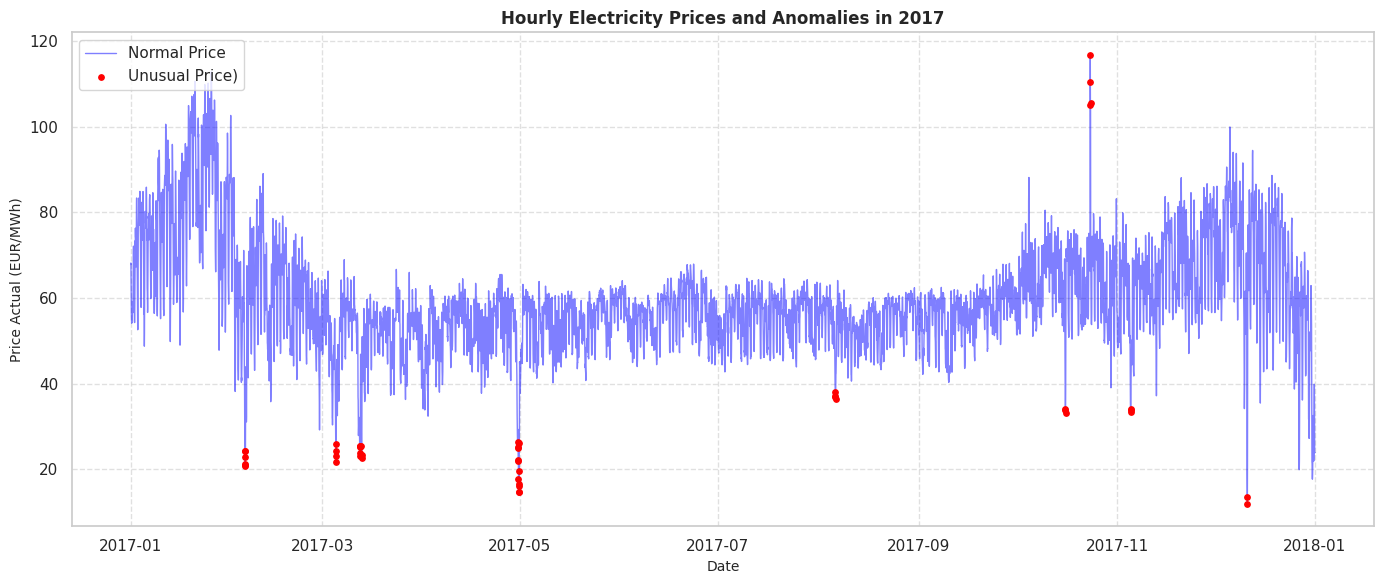

In [17]:
# BEGIN SOLUTION
#Calculates z-score of 'price actual' based off year-month's mean and std
mean_ym = df_clean.groupby(['year', 'month'])['price actual'].transform('mean')
std_ym = df_clean.groupby(['year', 'month'])['price actual'].transform('std')

#Creates the 'price_z' column and sets up its calculation
df_clean['price_z'] = (df_clean['price actual'] - mean_ym) / std_ym

#Cleans up NaN values into a 0
df_clean['price_z'] = df_clean['price_z'].fillna(0)

#Detects unusual hours by checking if z-scores
df_clean['is_unusual'] = df_clean['price_z'].abs() > 3

total_unusual = df_clean['is_unusual'].sum()
print(f"Total number of unusual hours: {total_unusual}\n")

unusual_per_year = df_clean[df_clean['is_unusual']].groupby('year').size()
print("Number of unusual hours per year:")
print(unusual_per_year)

print("\n--- 10 Anomaly Hours ---")

#Cleans up filtered unusual rows to match index list order
extreme_unusual = df_clean[df_clean['is_unusual']].reindex(
    #Displays data in descending (largest to smallest) order
    df_clean[df_clean['is_unusual']]['price_z'].abs().sort_values(ascending=False).index
).head(10)

display(extreme_unusual[['price actual', 'price_z', 'total load actual']])

top_year = unusual_per_year.idxmax()
print(f"\nPlotting anomalies for the year with the most unusual hours: {top_year}")

#Acts as filter for new 'df_top_year' and 'df_unusual_year'
df_top_year = df_clean[df_clean['year'] == top_year]
df_unusual_year = df_top_year[df_top_year['is_unusual']]

plt.figure(figsize=(14, 6))
plt.plot(df_top_year.index, df_top_year['price actual'], label='Normal Price', color='blue', alpha=0.5, linewidth=1)
plt.scatter(df_unusual_year.index, df_unusual_year['price actual'], label='Unusual Price)', color='red', s=15, zorder=5)

plt.title(f'Hourly Electricity Prices and Anomalies in {top_year}', fontsize=12, fontweight='bold')
plt.xlabel('Date', fontsize=10)
plt.ylabel('Price Actual (EUR/MWh)', fontsize=10)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()
# END SOLUTION

In [18]:
#Ensures that new columns are created in df_clean
assert 'price_z' in df_clean.columns, "Error: 'price_z' column not found in df_clean"
assert 'is_unusual' in df_clean.columns, "Error: 'is_unusual' column not found in df_clean"


## 11: Anomaly detection - IQR and forecast problems

a) Detect unusual `price actual` values again, this time with the IQR method (outside `Q1 - 1.5 x IQR` and `Q3 + 1.5 x IQR`), also per year-month. Print how many hours are flagged by: both methods, only the z-score method, and only the IQR method.

b) Find the "problematic forecast" hours where the absolute `load_forecast_error` is more than 5% of `total load actual`. Print the number of problematic hours per year.

In [19]:
# BEGIN SOLUTION

#Calculates the 25th percentile (Q1) for data inside each year-month group
q1_ym = df_clean.groupby(['year', 'month'])['price actual'].transform(lambda x: x.quantile(0.25))

#Calculates the 75th percentile (Q3) for data inside each year-month group
q3_ym = df_clean.groupby(['year', 'month'])['price actual'].transform(lambda x: x.quantile(0.75))
iqr_ym = q3_ym - q1_ym

#Establishes floor threshold where prices below the limit is unusually low
iqr_lower = q1_ym - 1.5 * iqr_ym
#Establishes ceiling threshold where prices below the limit is unusually high
iqr_upper = q3_ym + 1.5 * iqr_ym

#Creates the 'is_unusual_iqr' column and sets up its calculation
df_clean['is_unusual_iqr'] = (df_clean['price actual'] < iqr_lower) | (df_clean['price actual'] > iqr_upper)

#Provides total count of hours from true/false value conversion for optimized load
both_methods = (df_clean['is_unusual'] & df_clean['is_unusual_iqr']).sum()
only_zscore = (df_clean['is_unusual'] & ~df_clean['is_unusual_iqr']).sum()
only_iqr = (~df_clean['is_unusual'] & df_clean['is_unusual_iqr']).sum()

print("--- Anomaly Detection Method Comparison ---")
print(f"Hours flagged by BOTH methods: {both_methods}")
print(f"Hours flagged ONLY by Z-score method: {only_zscore}")
print(f"Hours flagged ONLY by IQR method: {only_iqr}\n")

#Creates the 'is_problematic_forecast' column and sets up its calculation
df_clean['is_problematic_forecast'] = df_clean['load_forecast_error'].abs() > (0.05 * df_clean['total load actual'])
problematic_per_year = df_clean[df_clean['is_problematic_forecast']].groupby('year').size()

print("Problematic Forecast Hours per Year")
print(problematic_per_year)
# END SOLUTION

--- Anomaly Detection Method Comparison ---
Hours flagged by BOTH methods: 146
Hours flagged ONLY by Z-score method: 6
Hours flagged ONLY by IQR method: 209

Problematic Forecast Hours per Year
year
2015    127
2016     62
2017     54
2018     30
dtype: int64


In [20]:
#Verify that new columns were created in 'df_clean'
assert 'is_unusual_iqr' in df_clean.columns, "Error: 'is_unusual_iqr' column is missing from df_clean."
assert 'is_problematic_forecast' in df_clean.columns, "Error: 'is_problematic_forecast' column is missing from df_clean."

#Verify that every row flagged as a problematic forecast strictly exceeds the 5% threshold
problematic_subset = df_clean[df_clean['is_problematic_forecast']]
if not problematic_subset.empty:
    #Checks every line if values are above the 0.05 threshold
    assert (problematic_subset['load_forecast_error'].abs() > (0.05 * problematic_subset['total load actual'])).all(), \
        "Assertion Failed: Found rows marked as problematic forecast with error <= 5% of total load."
print("All test cases passed, there are no incorrect values!")

All test cases passed, there are no incorrect values!


Compare the two anomaly detection methods. Which one is more appropriate for `price actual`, and why? (Hint: look back at your answer about skewness in question 4.) Write your answer in the Markdown cell below.

#### START.
Your analysis / interpretation goes here:



#### END.

## 12: Correlation analysis

For the variables `price actual`, `price day ahead`, `total load actual`, `generation fossil gas`, `generation fossil hard coal`, `generation fossil brown coal/lignite`, `generation nuclear`, `generation wind onshore`, `generation solar`, `generation hydro water reservoir` and `renewable_share`:

- calculate the **Pearson** and the **Spearman** correlation matrices and show them as two annotated seaborn heatmaps, side by side, using a diverging colour map centred at 0
- calculate the correlation between `price actual` and `generation wind onshore` separately for **winter** (December-February) and **summer** (June-August)

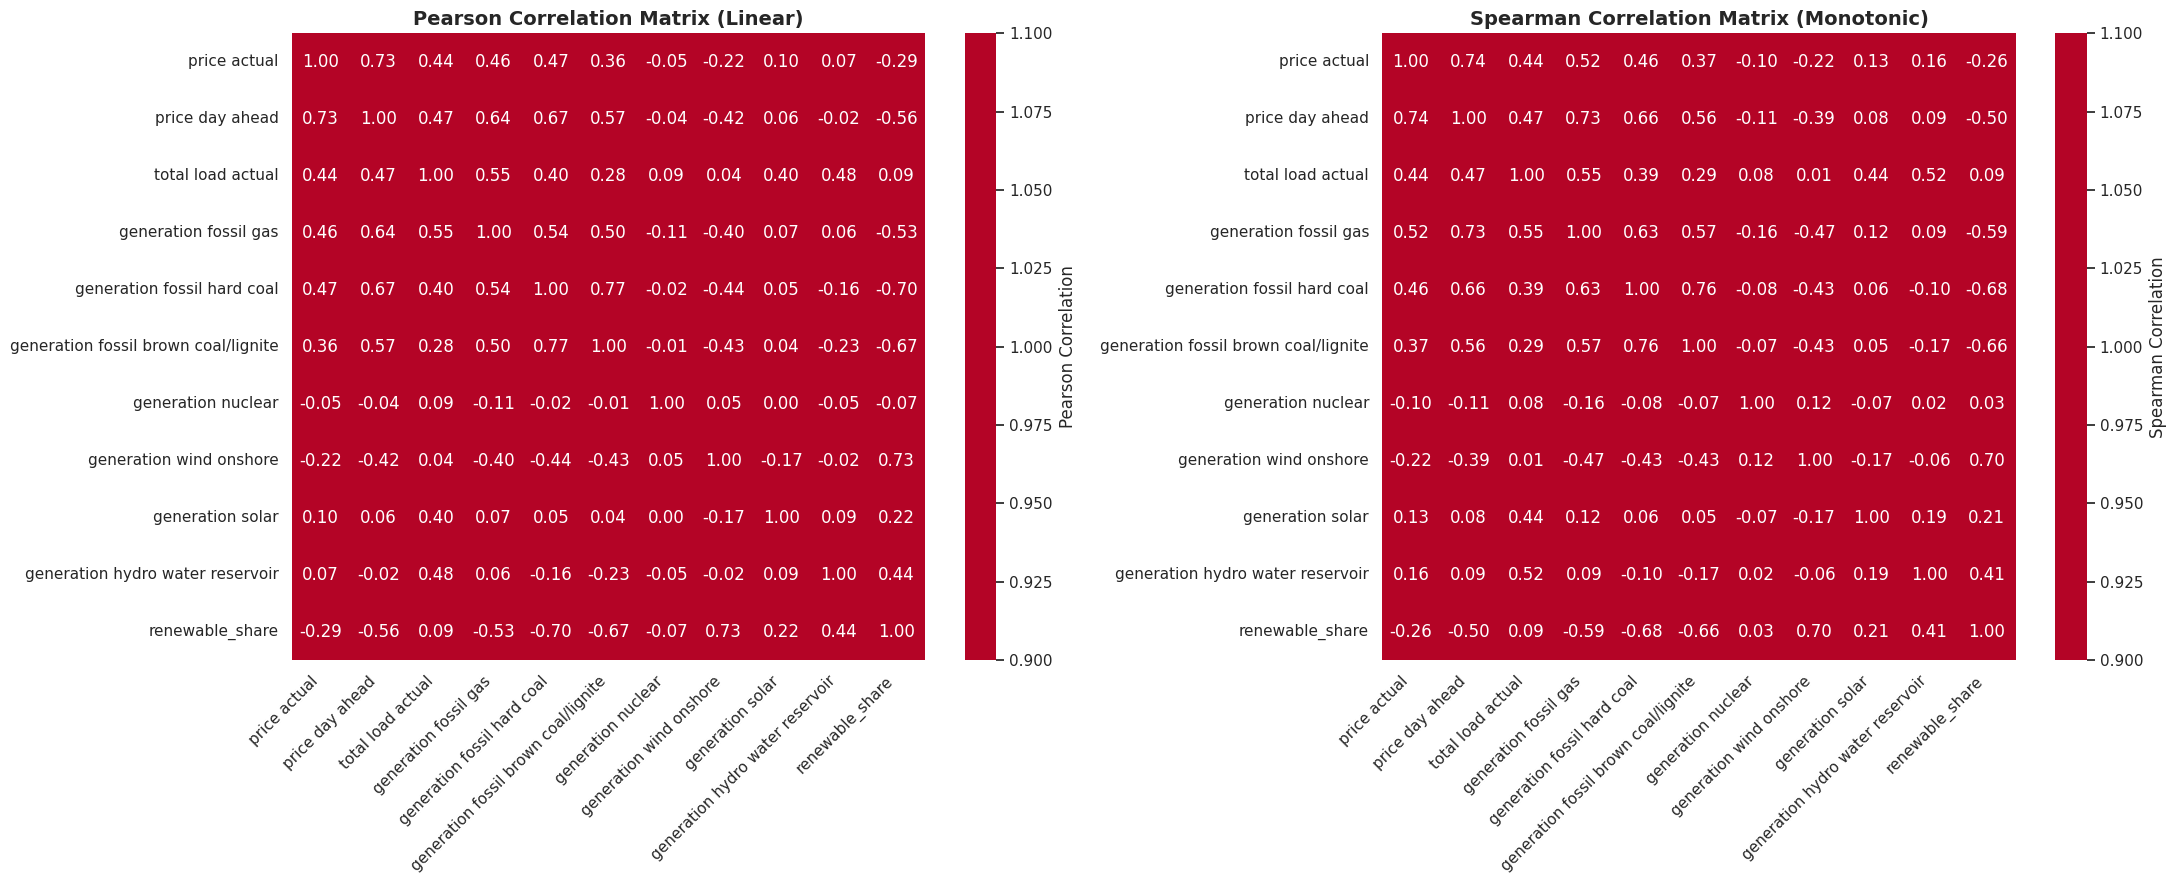

--- Seasonal Correlation: Price Actual vs. Generation Wind Onshore ---
Winter (Dec-Feb) Pearson Correlation: -0.1873
Summer (Jun-Aug) Pearson Correlation: -0.2752


In [21]:
# BEGIN SOLUTION
#Define variables for correlation analysis
cols_to_correlate = [
    'price actual', 'price day ahead', 'total load actual',
    'generation fossil gas', 'generation fossil hard coal',
    'generation fossil brown coal/lignite', 'generation nuclear',
    'generation wind onshore', 'generation solar',
    'generation hydro water reservoir', 'renewable_share'
]

#Checks column for column to ensure only existing columns are selected
valid_cols = [c for c in cols_to_correlate if c in df_clean.columns]

#Calculates pearson and spearman correlation matrices
corr_pearson = df_clean[valid_cols].corr(method='pearson')
corr_spearman = df_clean[valid_cols].corr(method='spearman')

#Sets up plot for side-by-side graphs displayed
fig, axes = plt.subplots(1,2, figsize=(22, 9))

sns.heatmap(
    corr_pearson, annot=True, fmt='.2f', cmap='coolwarm', center=0,
    #Provides hard limit on color scale between -1 to +1
    ax=axes[0], cbar_kws={'label': 'Pearson Correlation'}, vmin=1, vmax=1
)
axes[0].set_title('Pearson Correlation Matrix (Linear)', fontsize=14, fontweight='bold')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)

#Sets up heatmap
sns.heatmap(
    corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', center=0,
    #Provides hard limit on color scale between -1 to +1
    ax=axes[1], cbar_kws={'label': 'Spearman Correlation'}, vmin=1, vmax=1
)
axes[1].set_title('Spearman Correlation Matrix (Monotonic)', fontsize=14, fontweight='bold')

#Prevents collision by setting x-axis 45 degrees sideways
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0)

plt.tight_layout()
plt.show()

#Sets up filters to isolate specific seasons from the months
winter_mask = df_clean['month'].isin([12, 1, 2])
summer_mask = df_clean['month'].isin([6, 7, 8])

#Calculates pearson for specific months only
corr_winter = df_clean.loc[winter_mask, 'price actual'].corr(df_clean.loc[winter_mask, 'generation wind onshore'], method='pearson')
corr_summer = df_clean.loc[summer_mask, 'price actual'].corr(df_clean.loc[summer_mask, 'generation wind onshore'], method='pearson')

print("--- Seasonal Correlation: Price Actual vs. Generation Wind Onshore ---")
print(f"Winter (Dec-Feb) Pearson Correlation: {corr_winter:.4f}")
print(f"Summer (Jun-Aug) Pearson Correlation: {corr_summer:.4f}")
# END SOLUTION

#### START.
Describe the outputs. When do Pearson and Spearman differ, and why? Does a strong correlation show that one variable causes the other?



#### END.

# Section D: Big Data Analysis with PySpark

In this section you will use PySpark and the `fuel_in_france_2026_01_to_2026_09` dataset (either .csv or .parquet).

Note 1: Work through each question in order (later questions build on DataFrames and columns created in earlier ones).

Note 2: After question 19, there is a single Markdown cell for your analysis and interpretation of findings for questions 15-19.

### Start a Spark Session
Every PySpark script needs a `SparkSession`. This is the entry point to using Spark. Create a session named as your student ID. For instance, if your student ID is 12345678, the session must be named `12345678`.

In [22]:
# BEGIN SOLUTION
#Initializes SparkSession
spark = SparkSession.builder \
    .appName("26007815") \
    .getOrCreate()

#Verify if session is running
print(f"Spark Session successfully initialized!")
print(f"App Name: {spark.sparkContext.appName}")
print(f"Spark Version: {spark.version}")
# END SOLUTION

Spark Session successfully initialized!
App Name: 26007815
Spark Version: 4.0.4


## 13: Loading the fuel dataset and defining a schema

a) Load the dataset into a Spark DataFrame named `df_raw`, using `header=True` and `inferSchema=True`. Print its schema and measure the time taken to load it.

b) Now define an explicit schema (`StructType`) where `station_id`, `departement`, `regioncode` and `zipcode` are `StringType`, `rate_date` and `brent_date` are `StringType` (they are converted for you after question 14), and all numerical columns are `DoubleType`. Load the dataset again using your schema into a Spark DataFrame named `df_fuel`. Print its schema and measure the time taken to load it.

c) Some `zipcode` values have lost their leading `0` (for example `1000` instead of `01000`). Fix them in `df_fuel` so that every zipcode has 5 characters (hint: `F.lpad`).

d) Print the total number of rows and the number of partitions of `df_fuel`.

Note: if you choose the Parquet file, `header` and `inferSchema` do not apply, because Parquet stores its own schema. In (a), load the file and print its stored schema; in (b), apply your explicit schema by casting the columns (`.cast()`).

In [66]:
from os import statvfs_result
# BEGIN SOLUTION
#Sets up 'df_raw' based of parquet dataset
start_time = time.time()
df_raw = spark.read.parquet("fuel_in_france_2026_01_to_2026_09.parquet")

df_raw.printSchema()
time_raw = time.time() - start_time

#Sets up dataset loadtimes to 4 decimal places
print(f"Time taken to load df_raw: {time_raw:.4f} seconds\n")

#Sets up 'df_fuel' based of parquet dataset
start_time = time.time()
df_fuel = spark.read.parquet("fuel_in_france_2026_01_to_2026_09.parquet")

#Reference list for column names that requires StringType
string_cols = [
    'station_id', 'nom', 'commune', 'marque',
    'departement', 'regioncode', 'zipcode',
    'address', 'fuel_name', 'rate_date',
    'brent_date', 'source_file'
]

#Classes column data types as string (StringType) or numbers (DoubleType)
for col_name in df_fuel.columns:
  if col_name in string_cols:
    #Updates existing column's data type
    df_fuel = df_fuel.withColumn(col_name, F.col(col_name).cast(StringType()))
  else:
    df_fuel = df_fuel.withColumn(col_name, F.col(col_name).cast(DoubleType()))

df_fuel.printSchema()
time_fuel = time.time() - start_time
print(f"Time taken to load and cast df_fuel:{time_fuel:.4f} seconds\n")
#Updates zipcodes to be 5 digits if it isnt
df_fuel = df_fuel.withColumn('zipcode', F.lpad(F.col('zipcode'), 5, '0'))

#Creates partitions/smaller chunks to optimize load/memory usage
total_rows = df_fuel.count()
num_partitions = df_fuel.rdd.getNumPartitions()

print(f"Total number of rows: {total_rows:,}")
print(f"Number of partitions: {num_partitions}")
# END SOLUTION

root
 |-- rate_date: string (nullable = true)
 |-- station_id: long (nullable = true)
 |-- nom: string (nullable = true)
 |-- commune: string (nullable = true)
 |-- marque: string (nullable = true)
 |-- departement: string (nullable = true)
 |-- regioncode: long (nullable = true)
 |-- zipcode: long (nullable = true)
 |-- address: string (nullable = true)
 |-- coordlatitude: double (nullable = true)
 |-- coordlongitude: double (nullable = true)
 |-- fuel_name: string (nullable = true)
 |-- price: double (nullable = true)
 |-- brent_date: string (nullable = true)
 |-- brent_rate: double (nullable = true)
 |-- brent_rate_eur: double (nullable = true)
 |-- source_file: string (nullable = true)

Time taken to load df_raw: 0.1596 seconds

root
 |-- rate_date: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- nom: string (nullable = true)
 |-- commune: string (nullable = true)
 |-- marque: string (nullable = true)
 |-- departement: string (nullable = true)
 |-- regioncod

In [24]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.



Compare the two schemas and the two loading times. Why is an explicit schema important for this dataset (hint: look at `zipcode` and `departement`)? Write your answer in the Markdown cell below.

#### START.
Your analysis / interpretation goes here:



#### END.

## 14: Understanding the data and data quality

Using `df_fuel`, report:
- the number of missing values in each column, calculated in a **single pass** over the data (hint: something like `F.sum(F.col(c).isNull().cast("int"))` for every column inside one `.select()`)
- the number of distinct stations and the number of distinct brands (`marque`)
- the number of rows for each `fuel_name`
- the number of exact duplicate rows

Then remove the exact duplicate rows, and remove rows where `price` is missing, less than or equal to 0, or greater than 5 (EUR per litre). Save the result back to `df_fuel` and print the new number of rows.

In [74]:
# BEGIN SOLUTION
#Sets up a loop consisting of instructions for every column
missing_exprs = [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df_fuel.columns]
missing_counts = df_fuel.select(missing_exprs).collect()[0].asDict()

print("Missing Values per Column")
#Sets up display loop for number of missing rows
for col, count in missing_counts.items():
    print(f"{col}: {count}")
print()

num_stations = df_fuel.select('station_id').distinct().count()
num_brands = df_fuel.select('marque').distinct().count()

print(f"Number of distinct stations: {num_stations}")
print(f"Number of distinct brands: {num_brands}\n")

print("Row Count per Fuel Name")

#Executes summmary results by grouping and counting total row counts
fuel_counts = df_fuel.groupBy('fuel_name').count().collect()
for row in fuel_counts:
    print(f"  {row['fuel_name']}: {row['count']:,}")
print()

total_rows_before = df_fuel.count()
unique_df = df_fuel.dropDuplicates()
num_duplicates = total_rows_before - unique_df.count()

print(f"Number of exact duplicate rows: {num_duplicates:,}\n")

#Keeps only rows that are relevant to conditions and drops the rest
df_fuel = unique_df.filter(
    F.col('price').isNotNull() &
    (F.col('price') > 0) &
    (F.col('price') <= 5)
)

new_total_rows = df_fuel.count()
print(f"New number of rows after cleaning: {new_total_rows:,}")
# END SOLUTION

ERROR:root:KeyboardInterrupt while sending command.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/py4j/java_gateway.py", line 1038, in send_command
    response = connection.send_command(command)
  File "/usr/local/lib/python3.13/dist-packages/py4j/clientserver.py", line 535, in send_command
    answer = smart_decode(self.stream.readline()[:-1])
                          ~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/socket.py", line 723, in readinto
    return self._sock.recv_into(b)
           ~~~~~~~~~~~~~~~~~~~~^^^
KeyboardInterrupt


KeyboardInterrupt: 

In [26]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.



Considering this dataset, what other exploratory data analysis would you do to have a better understanding of the dataset? Write them as bullet points in the Markdown cell below.

#### START.
Your analysis / interpretation goes here:



#### END.

### Provided code: date conversion (not marked)

`rate_date` and `brent_date` are stored as text, and the date format is not the same across the whole dataset (for example `02/01/2026 00:01` in some rows and `2026-01-02 06:09:09` in others). Run the cell below **without changing it**. It adds the columns you need in the next questions:

- `rate_ts` (`TimestampType`): date and time of the price record
- `rate_day` (`DateType`): date of the price record
- `day_of_week` and `hour`: derived from `rate_ts`
- `brent_date` is converted into `DateType`

It also caches `df_fuel` in memory, as the next questions reuse it many times.

In [64]:
# BEGIN SOLUTION

# END SOLUTION

In [28]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.



## 15: Aggregation - fuel types and geography

a) For each `fuel_name`, calculate: number of records, number of distinct stations, mean, standard deviation, minimum and maximum `price` (rounded to 3 decimal places). Sort by mean price.

b) For `Gazole` and `E10` only, calculate the mean `price` for each `regioncode`, and pivot the result so that each fuel is a column. Sort by the mean `Gazole` price, descending.

c) Considering only departments with at least 30 distinct stations, which `departement` has the highest mean `Gazole` price, and which has the lowest?

In [72]:
# BEGIN SOLUTION
# Your code here with comments or explanation
df_fuel = spark.read.parquet("fuel_in_france_2026_01_to_2026_09.parquet")

# 2. Explicitly cast numerical columns and pad zipcodes safely
numerical_cols = ['price', 'coordlatitude', 'coordlongitude', 'brent_rate', 'brent_rate_eur']

for col_name in numerical_cols:
    if col_name in df_fuel.columns:
        df_fuel = df_fuel.withColumn(col_name, F.col(col_name).cast(DoubleType()))

if 'zipcode' in df_fuel.columns:
    df_fuel = df_fuel.withColumn('zipcode', F.lpad(F.col('zipcode'), 5, '0'))

# 3. Clean dataset: remove exact duplicates and invalid prices
df_fuel = df_fuel.dropDuplicates().filter(
    F.col('price').isNotNull() &
    (F.col('price') > 0) &
    (F.col('price') <= 5)
)


# --- Part a: Aggregations by fuel_name ---
df_15a = df_fuel.groupBy('fuel_name').agg(
    F.count('*').alias('num_records'),
    F.countDistinct('station_id').alias('num_distinct_stations'),
    F.round(F.mean('price'), 3).alias('mean_price'),
    F.round(F.stddev('price'), 3).alias('stddev_price'),
    F.round(F.min('price'), 3).alias('min_price'),
    F.round(F.max('price'), 3).alias('max_price')
).orderBy(F.col('mean_price').asc())

print("--- Question 15a: Aggregations by Fuel Name ---")
df_15a.show(20, truncate=False)


# --- Part b: Mean price by regioncode for Gazole and E10, pivoted ---
df_15b = df_fuel.filter(F.col('fuel_name').isin('Gazole', 'E10')) \
    .groupBy('regioncode') \
    .pivot('fuel_name', ['Gazole', 'E10']) \
    .agg(F.round(F.mean('price'), 3)) \
    .orderBy(F.col('Gazole').desc())

print("--- Question 15b: Pivoted Mean Prices for Gazole and E10 by Region ---")
df_15b.show(20, truncate=False)


# --- Part c: Departments with >= 30 stations, highest and lowest mean Gazole price ---
df_15c = df_fuel.filter(F.col('fuel_name') == 'Gazole') \
    .groupBy('departement') \
    .agg(
        F.round(F.mean('price'), 3).alias('mean_price'),
        F.countDistinct('station_id').alias('distinct_stations')
    ) \
    .filter(F.col('distinct_stations') >= 30)

print("--- Question 15c: Highest and Lowest Mean Gazole Price Departments (>= 30 Stations) ---")
print("Highest Mean Gazole Price:")
df_15c.orderBy(F.col('mean_price').desc()).show(1, truncate=False)

print("Lowest Mean Gazole Price:")
df_15c.orderBy(F.col('mean_price').asc()).show(1, truncate=False)
# END SOLUTION

--- Question 15a: Aggregations by Fuel Name ---
+---------+-----------+---------------------+----------+------------+---------+---------+
|fuel_name|num_records|num_distinct_stations|mean_price|stddev_price|min_price|max_price|
+---------+-----------+---------------------+----------+------------+---------+---------+
|E85      |440661     |4152                 |0.84      |0.09        |0.383    |2.299    |
|GPLc     |201948     |1676                 |1.03      |0.097       |0.585    |2.319    |
|E10      |984336     |8164                 |1.924     |0.157       |1.234    |2.99     |
|SP95     |213342     |3801                 |1.962     |0.154       |1.216    |2.99     |
|SP98     |901740     |8480                 |2.011     |0.16        |1.207    |2.99     |
|Gazole   |1170344    |10022                |2.039     |0.237       |1.2      |2.999    |
+---------+-----------+---------------------+----------+------------+---------+---------+

--- Question 15b: Pivoted Mean Prices for Gazole an

## 16: Brand comparison

For `Gazole` only, calculate the mean `price` and the number of distinct stations for each `marque`. Keep only brands with at least 50 distinct stations. Show the 5 cheapest and the 5 most expensive brands.

In [30]:
# BEGIN SOLUTION
# Your code here with comments or explanation


# END SOLUTION

## 17: Time-based analysis with window functions

a) Calculate the daily national mean price for each `fuel_name` and each `rate_day`. Save the result in a DataFrame named `daily_prices`.

b) For each `fuel_name`, calculate a 7-day (trailing, inclusive) moving average of the daily mean price, ordered by `rate_day`. Add it to `daily_prices` in a column named `ma_7_price`. Show the result for `Gazole` only.

c) For each station and fuel, find its **most recent** price record. Save the result in a DataFrame named `latest_prices` (one row per `station_id` and `fuel_name`). Print its number of rows and show 10 rows.

d) Convert `daily_prices` (a small, aggregated DataFrame) into pandas and plot the daily mean price and `ma_7_price` of each fuel over time.

In [31]:
# BEGIN SOLUTION
# Your code here with comments or explanation


# END SOLUTION

In [32]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.



## 18: Anomaly detection at scale

A price may be normal for one fuel type and unusual for another, and prices change day by day. For each `fuel_name` and `rate_day`, calculate the mean and standard deviation of `price`, join them back to `df_fuel`, and calculate a z-score for every record in a new column `price_z`. Define "unusual" as records where `|price_z| > 3`.

- print the number of unusual records for each `fuel_name`
- show the 10 most extreme unusual records, including `nom`, `commune`, `marque`, `fuel_name`, `price` and `price_z`
- save all unusual records in Parquet format, in a folder named `fuel_price_anomalies`

In [33]:
# BEGIN SOLUTION
# Your code here with comments or explanation


# END SOLUTION

In [34]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.



## 19: Correlation - Brent crude oil and pump prices

a) Create a daily DataFrame with one row per `rate_day`, holding the national mean `Gazole` price, the national mean `E10` price and the `brent_rate_eur` for that day. Calculate the correlation between the mean `Gazole` price and `brent_rate_eur`, and between the mean `E10` price and `brent_rate_eur`.

b) Pump prices may react to crude oil prices with a delay. Using a window function (`F.lag`), calculate the correlation between the mean `Gazole` price on each day and `brent_rate_eur` from *k* days earlier, for *k* = 0, 1, 2, ..., 5. Which lag gives the strongest correlation?

Note: `brent_rate_eur` is missing on days without a Brent price (e.g. weekends). Make sure these days do not break your calculation.

In [35]:
# BEGIN SOLUTION
# Your code here with comments or explanation


# END SOLUTION

Your analysis / interpretation for PySpark tasks (15-19) go here. Discuss the results of the aggregations, the brand and regional differences, the anomalies you detected and the relationship between Brent and pump prices. Consider the limitations of the dataset and of your analysis.

#### START.
Your analysis / interpretation goes here:



#### END.

## 20: Storage

Write `df_fuel` to Parquet format, partitioned by `fuel_name`, in a folder named `fuel_parquet`.

In [36]:
# BEGIN SOLUTION
# Your code here with comments or explanation


# END SOLUTION

In [37]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.



#### START.
Your analysis / interpretation goes here:



#### END.

## 21: Your Final Reflection

In less than 800 words, reflect on how you approached this assessment, what was new to you and how you found solutions. Explain how you acted on the formative feedback you received during the module, and what you changed as a result.

Moreover, relate your experience on this assessment to Big Data's four Vs (volume, variety, velocity, and veracity). Choose 2 of them and give one concrete example from your own implementation for each (at least one example must come from Section D).

Finally, choose one of the UN Sustainable Development Goals (e.g. SDG 7 - Affordable and Clean Energy, or SDG 13 - Climate Action) and briefly explain how the kind of analysis you did in this assessment could support it.

#### START
Your reflection here:




#### END